# 02 · Cálculo multivariable y gradientes

**Objetivo:** derivar gradientes a mano, verificarlos numéricamente y entender
qué dice la Hessiana sobre la geometría de una función de pérdida.

Regla de oro antes de entrenar cualquier cosa escrita a mano: **gradient check**.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from common import set_seed, setup_style

setup_style()
rng = set_seed(42)
from applied_math import gradient_check, mse, mse_gradient, numerical_gradient

## 1. Diferencias finitas: hacia adelante vs. centrales

$$\frac{f(x+\varepsilon) - f(x)}{\varepsilon} = f'(x) + O(\varepsilon) \qquad
\frac{f(x+\varepsilon) - f(x-\varepsilon)}{2\varepsilon} = f'(x) + O(\varepsilon^2)$$

Pero $\varepsilon$ muy pequeño amplifica el error de redondeo ($\sim \epsilon_{máq}/\varepsilon$).
El error total tiene forma de V: hay un $\varepsilon$ óptimo.

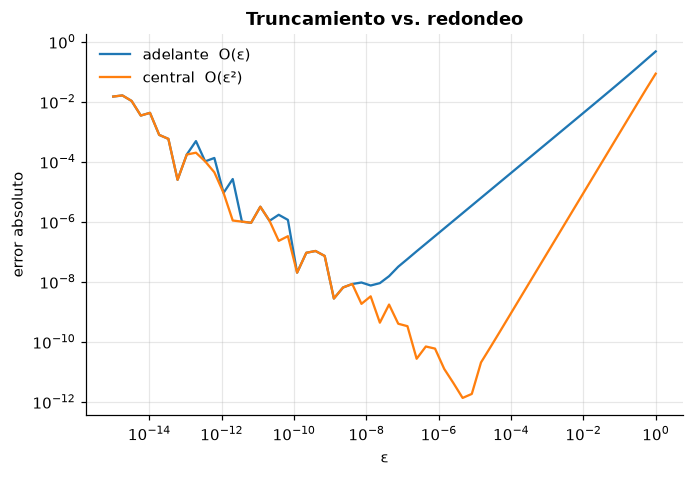

In [2]:
x0 = 1.0
eps = np.logspace(-15, 0, 60)
true = np.cos(x0)
fwd = np.abs((np.sin(x0 + eps) - np.sin(x0)) / eps - true)
ctr = np.abs((np.sin(x0 + eps) - np.sin(x0 - eps)) / (2 * eps) - true)

fig, ax = plt.subplots()
ax.loglog(eps, fwd, label="adelante  O(ε)")
ax.loglog(eps, ctr, label="central  O(ε²)")
ax.set_xlabel("ε")
ax.set_ylabel("error absoluto")
ax.set_title("Truncamiento vs. redondeo")
ax.legend();

In [3]:
print(f"ε óptimo adelante ≈ {eps[fwd.argmin()]:.0e}  (teoría ~ √ε_máq ≈ 1e-8)")
print(f"ε óptimo central  ≈ {eps[ctr.argmin()]:.0e}  (teoría ~ ∛ε_máq ≈ 6e-6)")

ε óptimo adelante ≈ 1e-09  (teoría ~ √ε_máq ≈ 1e-8)
ε óptimo central  ≈ 5e-06  (teoría ~ ∛ε_máq ≈ 6e-6)


## 2. Gradiente del MSE

$$L(w) = \tfrac{1}{n}\|Xw - y\|^2 \quad\Rightarrow\quad \nabla L(w) = \tfrac{2}{n}X^\top(Xw - y)$$

Derivación: $L = \tfrac1n (Xw-y)^\top(Xw-y)$; con $r = Xw - y$, $dL = \tfrac2n r^\top X\,dw$,
y el gradiente es la transpuesta del coeficiente de $dw$.

In [4]:
X = rng.normal(size=(50, 3))
y = rng.normal(size=50)
w = rng.normal(size=3)

err = gradient_check(lambda v: mse(v, X, y), lambda v: mse_gradient(v, X, y), w)
print(f"error relativo: {err:.2e}")

error relativo: 4.65e-11


Ahora un gradiente **mal** derivado (olvidando el factor 2). El gradient check lo delata
de inmediato, mientras que el entrenamiento solo se vería “un poco más lento”.

In [5]:
def wrong_grad(v):
    return X.T @ (X @ v - y) / len(y)


print(f"error relativo: {gradient_check(lambda v: mse(v, X, y), wrong_grad, w):.2e}")

error relativo: 3.33e-01


## 3. Hessiana y curvatura

Para el MSE, $H = \tfrac2n X^\top X$ es constante: la pérdida es una cuadrática.
Sus autovalores son las curvaturas en las direcciones principales, y
$\kappa = \lambda_{max}/\lambda_{min}$ controla qué tan “alargado” es el valle.

Comprobación: la Hessiana numérica es el jacobiano del gradiente.

In [6]:
H_analytic = 2 * X.T @ X / len(y)
H_numeric = np.stack(
    [numerical_gradient(lambda v, i=i: mse_gradient(v, X, y)[i], w) for i in range(3)]
)
print("max |H_a − H_n| =", np.abs(H_analytic - H_numeric).max())
lams = np.linalg.eigvalsh(H_analytic)
print("autovalores:", lams.round(3), "| κ =", round(lams[-1] / lams[0], 2))

max |H_a − H_n| = 2.095966733506316e-10
autovalores: [0.844 1.5   2.035] | κ = 2.41


## 4. Curvas de nivel según el condicionamiento

Features con escalas muy distintas → $\kappa$ grande → elipses alargadas.
El gradiente es perpendicular a las curvas de nivel, **no** apunta al mínimo: esta es la razón
geométrica de estandarizar features (se retoma en el notebook 03).

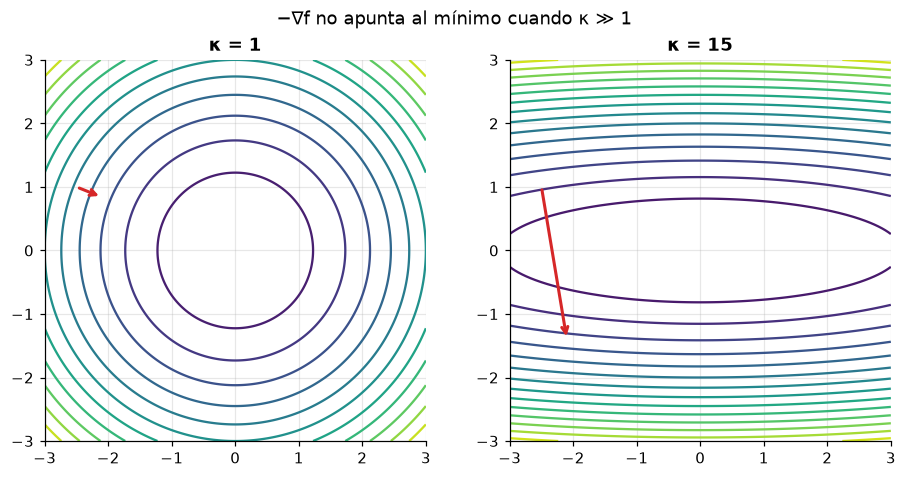

In [7]:
g = np.linspace(-3, 3, 200)
W1, W2 = np.meshgrid(g, g)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (a, b) in zip(axes, [(1, 1), (1, 15)], strict=True):
    Z = a * W1**2 + b * W2**2
    ax.contour(W1, W2, Z, levels=15, cmap="viridis")
    pt = np.array([-2.5, 1.0])
    gr = np.array([2 * a * pt[0], 2 * b * pt[1]])
    ax.annotate("", pt - 0.08 * gr, pt, arrowprops={"arrowstyle": "->", "color": "C3", "lw": 2})
    ax.set_title(f"κ = {b / a:g}")
    ax.set_aspect("equal")
fig.suptitle("−∇f no apunta al mínimo cuando κ ≫ 1");

## Para llevar

- Gradiente central con $\varepsilon \approx 10^{-6}$; error relativo $< 10^{-7}$ es buena señal.
- Verificar **siempre** gradientes escritos a mano antes de usarlos.
- La Hessiana mide curvatura; su número de condición predice la dificultad de la optimización.